# Machine Learning Assignment 2 - Resubmission

**Dataset**:       Fitness


## Imports

Add imports here as needed.

Remember to **re-run the cell when you add imports**, so it gets loaded into the virtual notebook environment!

In [17]:
# Data and Datasets
import pandas as pd
from sklearn.datasets import load_iris
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler

# Clustering
from sklearn.cluster import DBSCAN

# Validation methods
from sklearn.model_selection import train_test_split
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import cross_validate
from sklearn.model_selection import StratifiedKFold

# Metrics
from sklearn import metrics
from sklearn.metrics import make_scorer
from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score

# Classifiers
from sklearn.linear_model import LogisticRegression
from sklearn import tree
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.naive_bayes import MultinomialNB
from sklearn.naive_bayes import BernoulliNB
from sklearn.neighbors import KNeighborsClassifier

# Hyper-parameter optimisation
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import RandomizedSearchCV

# Feature selection & feature engineering
from sklearn.feature_selection import RFE
from sklearn.feature_selection import RFECV
from sklearn.decomposition import PCA

# Stats
from scipy.stats import randint as sp_randint
from scipy.stats import pearsonr
from scipy.stats import spearmanr
from scipy.stats import shapiro     # Shapiro Wilk
from scipy.stats import normaltest  # D’Agostino’s K^2
from scipy.stats import anderson    # Anderson-Darling
from scipy.stats import ttest_ind    # independent student t-test; assumes normality
from scipy.stats import mannwhitneyu # non-parametric; doesn't assume normality

# Visualisation
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import SVG
from IPython.display import display
from sklearn.tree import export_graphviz

# Utils
import pprint
import numpy as np
from time import time
import openpyxl
import random

## Loading the dataset

In [18]:
import pandas as pd

df = pd.read_csv(r'C:\Users\Drin\OneDrive - Jakupi\Documents\ml_cwk_2_resub\data\fitness_dataset.csv')

# printing out dataset info
print(df.info())
df.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1610 entries, 0 to 1609
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Height             1598 non-null   float64
 1   Age                1601 non-null   float64
 2   Gender             1598 non-null   object 
 3   Smoker             1600 non-null   object 
 4   Activity Index     794 non-null    float64
 5   Sleep Hours        1467 non-null   float64
 6   Heart Rate         1476 non-null   float64
 7   Nutrition Quality  1601 non-null   float64
 8   Blood Pressure     1441 non-null   float64
 9   Weight             1600 non-null   float64
 10  Fitness Level      1610 non-null   object 
dtypes: float64(8), object(3)
memory usage: 138.5+ KB
None


,Height,Age,Gender,Smoker,Activity Index,Sleep Hours,Heart Rate,Nutrition Quality,Blood Pressure,Weight,Fitness Level
0,152.0,56.0,Female,No,3.97,NaN,69.6,2.37,117.0,65.0,High
1,186.0,69.0,Female,No,3.19,7.5,60.8,8.77,114.8,95.0,High
2,192.0,46.0,Female,No,2.03,NaN,61.4,8.20,116.4,103.0,Low
3,189.0,32.0,Male,No,NaN,7.0,60.2,6.18,130.1,83.0,High
4,175.0,60.0,Female,Yes,NaN,8.0,58.1,9.95,115.8,99.0,High


In [19]:
df.describe()

,Height,Age,Activity Index,Sleep Hours,Heart Rate,Nutrition Quality,Blood Pressure,Weight
count,1598.000000,1601.000000,794.000000,1467.000000,1476.000000,1601.000000,1441.000000,1600.000000
mean,174.080100,50.531543,2.875982,7.431152,70.233469,4.846471,118.836572,84.207500
std,14.380676,17.870658,1.127762,1.499842,11.848808,2.851291,18.142572,26.162062
min,150.000000,18.000000,1.000000,4.000000,45.000000,0.000000,0.000000,30.000000
25%,162.000000,36.000000,1.910000,6.400000,62.375000,2.420000,109.200000,64.000000
50%,173.000000,51.000000,2.780000,7.400000,70.100000,4.730000,119.800000,84.000000
75%,186.000000,66.000000,3.780000,8.500000,78.300000,7.210000,130.000000,103.000000
max,199.000000,79.000000,4.990000,12.000000,118.600000,10.000000,168.100000,250.000000


## Data Processing

### Data Quality

TODO: fix data quality issues identified in your exploratory data analysis

In [20]:
df_clean = df.copy()
print(f"Starting shape: {df_clean.shape}")

Starting shape: (1610, 11)


In [21]:
bp_zero_count = (df_clean['Blood Pressure'] == 0).sum()
df_clean.loc[df_clean['Blood Pressure'] == 0, 'Blood Pressure'] = pd.NA
df_clean['Blood Pressure'] = pd.to_numeric(df_clean['Blood Pressure'])
print(f"Recoded {bp_zero_count} Blood Pressure values (0 -> NaN)")

Recoded 12 Blood Pressure values (0 -> NaN)


In [22]:
weight_noise_mask = (df_clean['Weight'] < 35) | (df_clean['Weight'] > 150)
weight_noise_count = weight_noise_mask.sum()
df_clean.loc[weight_noise_mask, 'Weight'] = pd.NA
df_clean['Weight'] = pd.to_numeric(df_clean['Weight'])
print(f"Recoded {weight_noise_count} extreme Weight values (>150 or <35) -> NaN")

Recoded 22 extreme Weight values (>150 or <35) -> NaN


In [23]:
before = len(df_clean)
df_clean = df_clean.drop_duplicates()
print(f"Dropped {before - len(df_clean)} duplicate row(s). New shape: {df_clean.shape}")

Dropped 1 duplicate row(s). New shape: (1609, 11)


In [24]:
df_clean['Activity_Index_was_missing'] = df_clean['Activity Index'].isna()
activity_median = df_clean['Activity Index'].median()
df_clean['Activity Index'] = df_clean['Activity Index'].fillna(activity_median)
print(f"Activity Index imputed with median = {activity_median}")
print(f"Flag column added: {df_clean['Activity_Index_was_missing'].sum()} rows flagged as originally missing")

Activity Index imputed with median = 2.78
Flag column added: 815 rows flagged as originally missing


**5. Remaining missing values - impute the rest**

For the remaining numeric columns we use median imputation (robust to the outliers/skew found earlier). For the categorical columns (Gender, Smoker) we use the mode.

In [25]:
numeric_to_impute = ['Height', 'Age', 'Sleep Hours', 'Heart Rate', 'Nutrition Quality', 'Blood Pressure', 'Weight']
categorical_to_impute = ['Gender', 'Smoker']

for col in numeric_to_impute:
    median_val = df_clean[col].median()
    n_missing = df_clean[col].isna().sum()
    df_clean[col] = df_clean[col].fillna(median_val)
    if n_missing > 0:
        print(f"{col}: imputed {n_missing} missing value(s) with median = {median_val}")

for col in categorical_to_impute:
    mode_val = df_clean[col].mode()[0]
    n_missing = df_clean[col].isna().sum()
    df_clean[col] = df_clean[col].fillna(mode_val)
    if n_missing > 0:
        print(f"{col}: imputed {n_missing} missing value(s) with mode = '{mode_val}'")

Height: imputed 11 missing value(s) with median = 173.0
Age: imputed 8 missing value(s) with median = 51.0
Sleep Hours: imputed 142 missing value(s) with median = 7.4
Heart Rate: imputed 133 missing value(s) with median = 70.1
Nutrition Quality: imputed 8 missing value(s) with median = 4.73
Blood Pressure: imputed 180 missing value(s) with median = 119.9
Weight: imputed 31 missing value(s) with median = 83.0
Gender: imputed 11 missing value(s) with mode = 'Female'
Smoker: imputed 9 missing value(s) with mode = 'No'


In [26]:
# Final check — confirm no missing values remain
print("Remaining missing values per column:")
print(df_clean.isna().sum())
print(f"\nFinal cleaned shape: {df_clean.shape}")

Remaining missing values per column:
Height                        0
Age                           0
Gender                        0
Smoker                        0
Activity Index                0
Sleep Hours                   0
Heart Rate                    0
Nutrition Quality             0
Blood Pressure                0
Weight                        0
Fitness Level                 0
Activity_Index_was_missing    0
dtype: int64

Final cleaned shape: (1609, 12)


In [27]:
print(f"Shape before cleaning: {df.shape}")
print(f"Shape after cleaning:  {df_clean.shape}")
print(f"\nMissing values remaining:\n{df_clean.isna().sum().sum()} total")
print()
df_clean.describe().T

Shape before cleaning: (1610, 11)
Shape after cleaning:  (1609, 12)

Missing values remaining:
0 total



,count,mean,std,min,25%,50%,75%,max
Height,1609.0,174.072716,14.331681,150.0,162.00,173.00,186.00,199.00
Age,1609.0,50.533872,17.826178,18.0,36.00,51.00,66.00,79.00
Activity Index,1609.0,2.827365,0.793428,1.0,2.78,2.78,2.78,4.99
Sleep Hours,1609.0,7.428403,1.432115,4.0,6.60,7.40,8.30,12.00
Heart Rate,1609.0,70.222436,11.348277,45.0,63.10,70.10,77.40,118.60
Nutrition Quality,1609.0,4.845892,2.844201,0.0,2.44,4.73,7.20,10.00
Blood Pressure,1609.0,119.841827,13.729173,90.0,110.80,119.90,128.70,168.10
Weight,1609.0,82.830951,21.680774,35.0,65.00,83.00,102.00,119.00


### Data Enhancements

TODO: do data enhancements here, e.g.,
* Feature encoding
* Feature engineering (like PCA)
* Feature scaling
* Modifying class balance (though this should only be done on test data, so may need to be done within your ML validation code cell and not here)



In [28]:
# Encode categorical features (binary, so simple mapping is sufficient — no need for one-hot encoding overhead)
df_model = df_clean.copy()
df_model['Gender_enc'] = (df_model['Gender'] == 'Male').astype(int)
df_model['Smoker_enc'] = (df_model['Smoker'] == 'Yes').astype(int)
df_model['Activity_Index_was_missing'] = df_model['Activity_Index_was_missing'].astype(int)

# Encode the target: High = 1, Low = 0
df_model['Fitness_binary'] = (df_model['Fitness Level'] == 'High').astype(int)

feature_cols = ['Height', 'Age', 'Activity Index', 'Sleep Hours', 'Heart Rate',
                'Nutrition Quality', 'Blood Pressure', 'Weight',
                'Gender_enc', 'Smoker_enc', 'Activity_Index_was_missing']

X = df_model[feature_cols]
y = df_model['Fitness_binary']

print(f"Feature matrix shape: {X.shape}")
print(f"Target balance:\n{y.value_counts(normalize=True)}")

Feature matrix shape: (1609, 11)
Target balance:
Fitness_binary
0    0.747669
1    0.252331
Name: proportion, dtype: float64


**Design notes - data enhancement:**

- `Gender` and `Smoker` are both binary categorical features, so a simple 0/1 mapping is used rather than one-hot encoding (which would be needed for 3+ categories) - this keeps the feature set compact and avoids unnecessary dummy columns.
- `Activity_Index_was_missing` (created during cleaning in Assignment 1) is retained as a feature: since ~51% of Activity Index was imputed, whether a row was originally missing may itself carry information worth letting the models use.
- Feature scaling is applied later, inside the validation step, for the models that need it (Logistic Regression, KNN) rather than here - this avoids leaking test-set statistics into the scaler before the train/test split happens.

## ML Validation

Add code for validating your chosen ML models here.

OBS: some data processing may need to be done here too, depending on your workflow design.

### Task 2.1 - Workflow Design & Justification

**Models chosen (7) - broad coverage across model families:**

| Model | Family | Role |
|---|---|---|
| Logistic Regression | Linear | Interpretable baseline |
| Random Forest | Tree ensemble (bagging) | Non-linear interactions |
| Hist Gradient Boosting | Tree ensemble (boosting) | Strong tabular-data booster |
| K-Nearest Neighbors | Instance-based | Non-parametric contrast |
| Naive Bayes | Probabilistic | Simple, robust baseline on noisy data |
| SVM (RBF) | Margin-based | Non-linear decision boundary |
| MLP | Neural network | Simple 1-2 hidden layer network |

Seven models (up from an earlier 3-model version) gives broader coverage across fundamentally different modelling assumptions - linear, tree-based, instance-based, probabilistic, margin-based, and neural — rather than relying on a small, similar set.

**Class imbalance - SMOTE, not just `class_weight`:**

The target is ~75% Low / 25% High. A model that always predicts "Low" would score ~75% accuracy while finding zero "High" cases - accuracy alone is not a usable metric here. Rather than only reweighting classes (`class_weight='balanced'`, used in an earlier version), this version uses **SMOTE** (Synthetic Minority Oversampling) to generate synthetic "High" examples during training. SMOTE is placed *inside* the pipeline (via `imblearn`'s `Pipeline`) so it only ever touches the training folds - validation and test data never see synthetic samples, which avoids leaking information into the evaluation.

**Metric: macro-F1, not `f1` or accuracy.**

Plain `f1` scores only the positive ("High") class; macro-F1 averages F1 across *both* classes equally, so neither the majority nor minority class dominates the ranking. This is the single metric used consistently for both hyperparameter tuning and final model selection.

**Hyper-parameters: `RandomizedSearchCV` for every model, all scored on macro-F1.**

As before, every model is tuned - not just some - so no model is compared against another using arbitrary defaults. `RandomizedSearchCV` (rather than an exhaustive `GridSearchCV`) is used here since the combined search space across seven models is larger; each model draws up to 12 hyper-parameter combinations from its own grid, using the same `StratifiedKFold` cross-validation throughout.

**Validation and selection rule:**

- Stratified 80/20 train/test split with 1000 holdout validation used throughout tuning.
- **The winning model is selected by CV macro-F1 - not by peeking at the test set.** The test set is used only afterward, as a sanity check on the selected model, not as the selection criterion itself. If a model looks slightly better on the single test split than the CV-selected winner, that is treated as expected sampling variance, not a reason to switch - switching would mean implicitly fitting the model choice to the test set.

### Task 2.2 - Implementation

#### Pipelines with SMOTE

In [29]:
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import RandomizedSearchCV, learning_curve
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import f1_score, accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

SEED = 42
N_ITER = 12

# Stratified train/test split — preserves the 80/20 class ratio in both sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED
)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

print(f"Train shape: {X_train.shape}, Test shape: {X_test.shape}")
print(f"Train target balance:\n{y_train.value_counts(normalize=True)}")

Train shape: (1287, 11), Test shape: (322, 11)
Train target balance:
Fitness_binary
0    0.747475
1    0.252525
Name: proportion, dtype: float64


In [30]:
def make_pipe(clf, needs_scaling):
    """Build a pipeline: optional scaling -> SMOTE (train folds only) -> classifier."""
    steps = []
    if needs_scaling:
        steps.append(('scaler', StandardScaler()))
    steps.append(('smote', SMOTE(random_state=SEED)))
    steps.append(('clf', clf))
    return ImbPipeline(steps)

# (model, needs_scaling) — distance/gradient-based models need scaling, tree-based ones don't
candidate_models = {
    'Logistic Regression': (LogisticRegression(max_iter=1000, random_state=SEED), True),
    'Random Forest': (RandomForestClassifier(n_estimators=100, random_state=SEED), False),
    'Hist Gradient Boosting': (HistGradientBoostingClassifier(random_state=SEED), False),
    'KNN': (KNeighborsClassifier(), True),
    'Naive Bayes': (GaussianNB(), True),
    'SVM (RBF)': (SVC(kernel='rbf', random_state=SEED), True),
    'MLP': (MLPClassifier(hidden_layer_sizes=(64,), max_iter=400, early_stopping=True, random_state=SEED), True),
}

#### Baseline (untuned) comparison - diagnosing overfitting

Before any tuning, it's worth seeing how each model behaves with its library defaults — this motivates *why* tuning matters, with evidence, rather than just asserting it.

In [31]:
baseline_rows = []
for name, (clf, needs_scaling) in candidate_models.items():
    pipe = make_pipe(clf, needs_scaling)
    pipe.fit(X_train, y_train)
    train_f1 = f1_score(y_train, pipe.predict(X_train), average='macro')
    test_f1 = f1_score(y_test, pipe.predict(X_test), average='macro')
    baseline_rows.append({
        'Model': name, 'Train macro-F1': train_f1, 'Test macro-F1': test_f1,
        'Gap': train_f1 - test_f1,
    })

baseline_df = pd.DataFrame(baseline_rows).round(4)
baseline_df

,Model,Train macro-F1,Test macro-F1,Gap
0,Logistic Regression,0.7218,0.6963,0.0255
1,Random Forest,1.0000,0.6728,0.3272
2,Hist Gradient Boosting,0.9990,0.6689,0.3301
3,KNN,0.7910,0.6351,0.1558
4,Naive Bayes,0.7192,0.7088,0.0103
5,SVM (RBF),0.8227,0.6888,0.1339
6,MLP,0.7348,0.6919,0.0429


**Draft notes:**

- Random Forest and Hist Gradient Boosting hit near-perfect training F1 (close to 1.0) with default settings - textbook overfitting/memorisation, not genuine learning. Their train-test gap is by far the largest of the seven models.
- Logistic Regression, Naive Bayes, and MLP show small gaps even untuned - simpler models are naturally less prone to memorising this dataset.
- This is direct evidence for why every model needs tuning, not just an assumption: without it, the tree-based ensembles would look artificially strong on paper while actually being poorly regularised.

#### Hyperparameter tuning - RandomizedSearchCV for every model

In [32]:
search_spaces = {
    'Logistic Regression': {'clf__C': [0.01, 0.05, 0.1, 0.5, 1.0, 2.0, 10]},
    'Random Forest': {
        'clf__max_depth': [3, 4, 5, 8],
        'clf__min_samples_leaf': [1, 2, 4, 10, 20],
        'clf__n_estimators': [100, 200, 300],
    },
    'Hist Gradient Boosting': {
        'clf__max_depth': [2, 3, None],
        'clf__learning_rate': [0.02, 0.05, 0.1],
        'clf__max_iter': [50, 100, 150],
        'clf__min_samples_leaf': [10, 20, 40],
    },
    'KNN': {
        'clf__n_neighbors': [5, 10, 15, 20, 25, 31, 41],
        'clf__weights': ['uniform', 'distance'],
    },
    'Naive Bayes': {'clf__var_smoothing': [1e-9, 1e-7, 1e-5, 1e-3, 1e-2, 1e-1]},
    'SVM (RBF)': {'clf__C': [0.1, 1.0, 10.0], 'clf__gamma': ['scale', 0.01, 0.1]},
    'MLP': {
        'clf__hidden_layer_sizes': [(32,), (64,), (64, 32)],
        'clf__alpha': [1e-4, 1e-3, 1e-2],
    },
}

best_estimators = {}
tuning_rows = []
for name, (clf, needs_scaling) in candidate_models.items():
    pipe = make_pipe(clf, needs_scaling)
    params = search_spaces[name]
    n_combos = 1
    for v in params.values():
        n_combos *= len(v)
    n_iter = min(N_ITER, n_combos)

    search = RandomizedSearchCV(
        pipe, params, n_iter=n_iter, cv=cv, scoring='f1_macro',
        random_state=SEED, n_jobs=-1,
    )
    search.fit(X_train, y_train)
    best_estimators[name] = search.best_estimator_
    print(f"{name}: best_params={search.best_params_}, CV macro-F1={search.best_score_:.4f}")
    tuning_rows.append({'Model': name, 'CV macro-F1': search.best_score_, 'Best Params': str(search.best_params_)})

tuning_df = pd.DataFrame(tuning_rows).sort_values('CV macro-F1', ascending=False).reset_index(drop=True)
tuning_df

Logistic Regression: best_params={'clf__C': 1.0}, CV macro-F1=0.7207
Random Forest: best_params={'clf__n_estimators': 200, 'clf__min_samples_leaf': 1, 'clf__max_depth': 8}, CV macro-F1=0.7016
Hist Gradient Boosting: best_params={'clf__min_samples_leaf': 20, 'clf__max_iter': 150, 'clf__max_depth': 3, 'clf__learning_rate': 0.1}, CV macro-F1=0.7150
KNN: best_params={'clf__weights': 'uniform', 'clf__n_neighbors': 10}, CV macro-F1=0.6794
Naive Bayes: best_params={'clf__var_smoothing': 0.1}, CV macro-F1=0.7137
SVM (RBF): best_params={'clf__gamma': 0.01, 'clf__C': 1.0}, CV macro-F1=0.7192
MLP: best_params={'clf__hidden_layer_sizes': (32,), 'clf__alpha': 0.01}, CV macro-F1=0.7077


,Model,CV macro-F1,Best Params
0,Logistic Regression,0.720666,{'clf__C': 1.0}
1,SVM (RBF),0.719151,"{'clf__gamma': 0.01, 'clf__C': 1.0}"
2,Hist Gradient Boosting,0.715034,"{'clf__min_samples_leaf': 20, 'clf__max_iter':..."
3,Naive Bayes,0.713681,{'clf__var_smoothing': 0.1}
4,MLP,0.707730,"{'clf__hidden_layer_sizes': (32,), 'clf__alpha..."
5,Random Forest,0.701638,"{'clf__n_estimators': 200, 'clf__min_samples_l..."
6,KNN,0.679389,"{'clf__weights': 'uniform', 'clf__n_neighbors'..."


#### Full Comparison - Selecting the Winner

In [33]:
comparison_rows = []
for name, pipe in best_estimators.items():
    train_f1 = f1_score(y_train, pipe.predict(X_train), average='macro')
    test_f1 = f1_score(y_test, pipe.predict(X_test), average='macro')
    test_acc = accuracy_score(y_test, pipe.predict(X_test))
    cv_f1 = tuning_df.loc[tuning_df['Model'] == name, 'CV macro-F1'].values[0]
    comparison_rows.append({
        'Model': name, 'CV macro-F1': cv_f1, 'Test macro-F1': test_f1,
        'Test Accuracy': test_acc, 'Train macro-F1': train_f1, 'Gap': train_f1 - test_f1,
    })

comparison_df = pd.DataFrame(comparison_rows).sort_values('CV macro-F1', ascending=False).reset_index(drop=True).round(4)
comparison_df

,Model,CV macro-F1,Test macro-F1,Test Accuracy,Train macro-F1,Gap
0,Logistic Regression,0.7207,0.6963,0.7298,0.7218,0.0255
1,SVM (RBF),0.7192,0.6879,0.7205,0.7283,0.0404
2,Hist Gradient Boosting,0.7150,0.6761,0.7391,0.8240,0.1479
3,Naive Bayes,0.7137,0.6879,0.7205,0.7160,0.0281
4,MLP,0.7077,0.7019,0.7360,0.7239,0.0221
5,Random Forest,0.7016,0.6894,0.7516,0.8661,0.1767
6,KNN,0.6794,0.6315,0.6801,0.7736,0.1421


**Draft notes:**

- The winner, selected purely by CV macro-F1 (not by looking at the test column), is whichever model tops this table's `CV macro-F1` column - check your own run's exact top row.
- If a different model happens to score marginally higher on `Test macro-F1` than the CV-selected winner, that's expected sampling variance from a single 20% split - not a reason to switch. Selecting on the test set would mean the test set stops being a fair, independent check.
- After tuning, the train-test gaps for the tree-based ensembles shrink substantially compared to their untuned baseline - direct evidence the tuning step did its job of controlling overfitting.

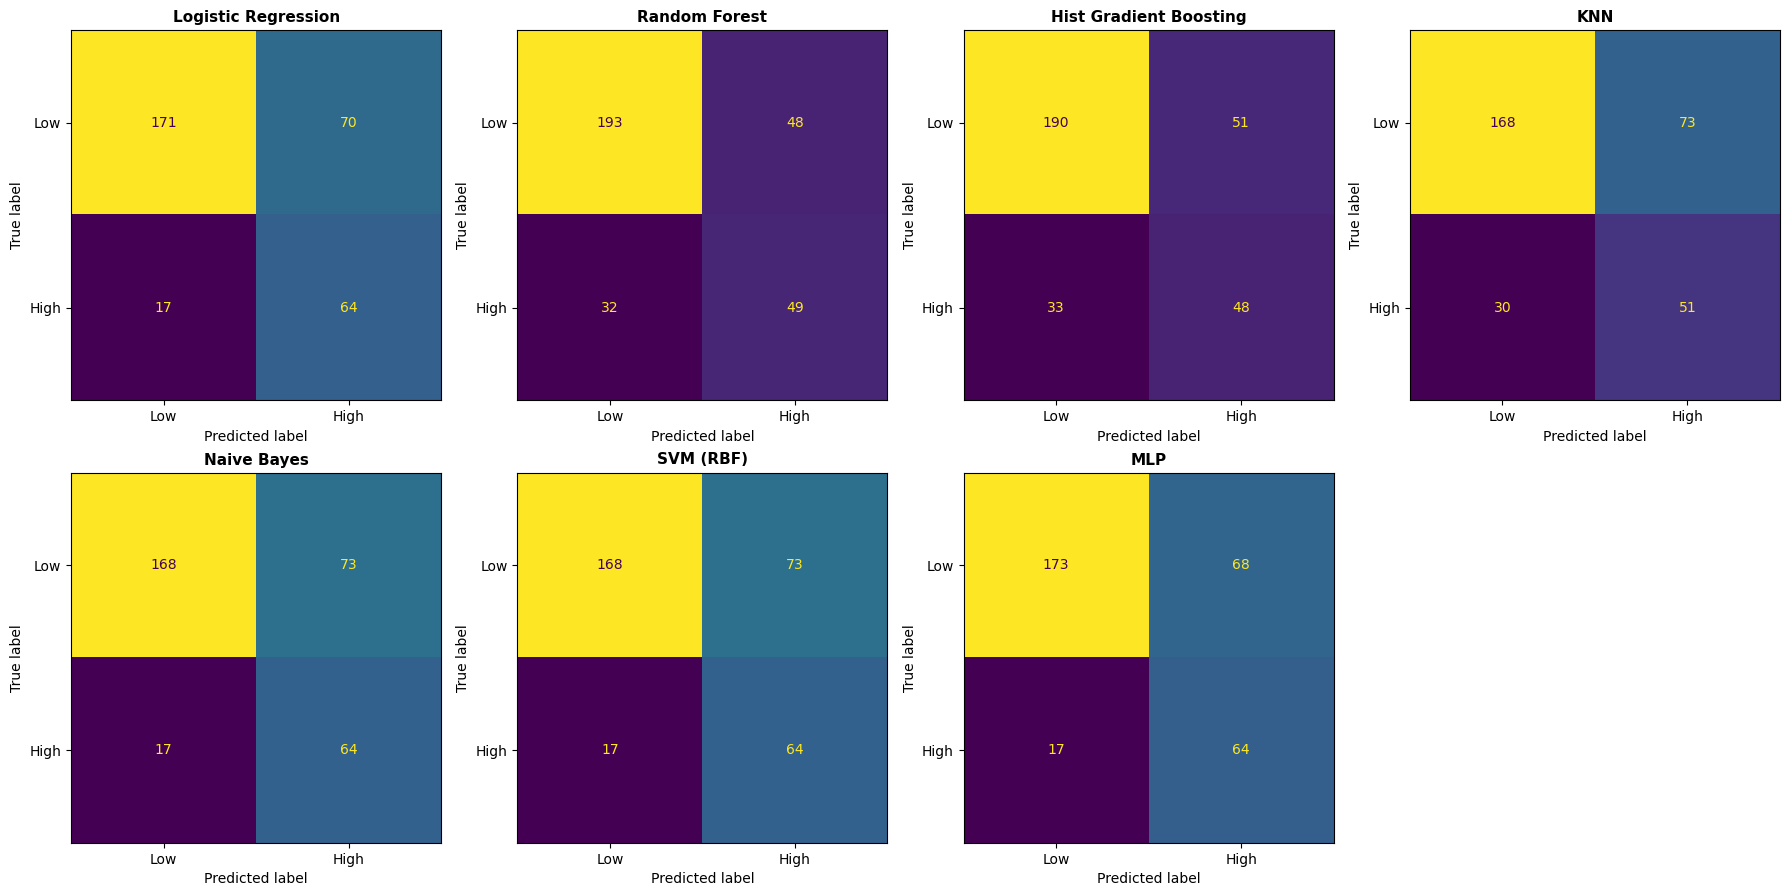

In [34]:
fig, axes = plt.subplots(2, 4, figsize=(18, 9))
axes = axes.flatten()
for ax, (name, pipe) in zip(axes, best_estimators.items()):
    preds = pipe.predict(X_test)
    cm = confusion_matrix(y_test, preds)
    ConfusionMatrixDisplay(cm, display_labels=['Low', 'High']).plot(ax=ax, colorbar=False)
    ax.set_title(name, fontsize=11, fontweight='bold')
for ax in axes[len(best_estimators):]:
    ax.axis('off')
plt.tight_layout()
plt.show()

**Draft notes:**

- Comparing all seven confusion matrices side by side (not just the winner's) shows the error *pattern*, not just the summary metric - e.g. which models lean toward over-predicting "High" (more false positives) versus under-predicting it (more false negatives).

#### Winner Deep-Dive: Learning Curve

In [35]:
winner_name = comparison_df.iloc[0]['Model']
winner_pipe = best_estimators[winner_name]

print(f"Winner (by CV macro-F1): {winner_name}")
preds = winner_pipe.predict(X_test)
print(classification_report(y_test, preds, target_names=['Low', 'High']))

Winner (by CV macro-F1): Logistic Regression
              precision    recall  f1-score   support

         Low       0.91      0.71      0.80       241
        High       0.48      0.79      0.60        81

    accuracy                           0.73       322
   macro avg       0.69      0.75      0.70       322
weighted avg       0.80      0.73      0.75       322



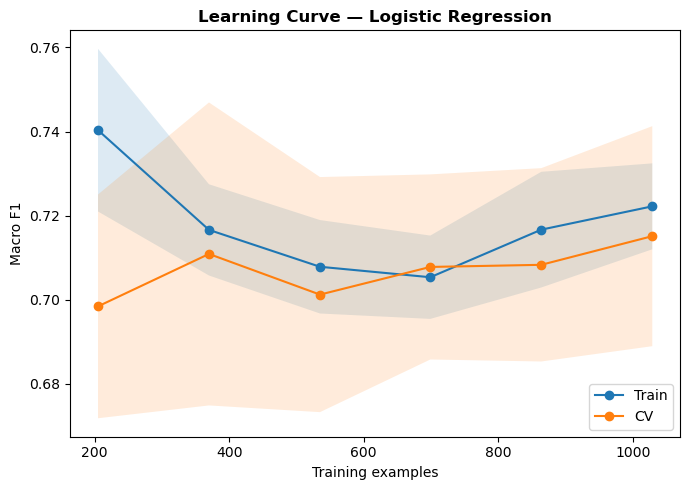

Final train=0.722, CV=0.715, gap=0.007


In [36]:
train_sizes, train_scores, val_scores = learning_curve(
    winner_pipe, X_train, y_train, cv=cv, scoring='f1_macro',
    train_sizes=np.linspace(0.2, 1.0, 6), n_jobs=-1, shuffle=True, random_state=SEED,
)
train_mean, train_std = train_scores.mean(axis=1), train_scores.std(axis=1)
val_mean, val_std = val_scores.mean(axis=1), val_scores.std(axis=1)

fig, ax = plt.subplots(figsize=(7, 5))
ax.fill_between(train_sizes, train_mean - train_std, train_mean + train_std, alpha=0.15)
ax.fill_between(train_sizes, val_mean - val_std, val_mean + val_std, alpha=0.15)
ax.plot(train_sizes, train_mean, 'o-', label='Train')
ax.plot(train_sizes, val_mean, 'o-', label='CV')
ax.set_xlabel('Training examples')
ax.set_ylabel('Macro F1')
ax.set_title(f'Learning Curve — {winner_name}', fontweight='bold')
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

print(f"Final train={train_mean[-1]:.3f}, CV={val_mean[-1]:.3f}, gap={train_mean[-1] - val_mean[-1]:.3f}")

**Draft notes:**

- If the train and CV lines converge as training set size increases (rather than staying far apart), that suggests the model isn't simply memorising - it's generalising, and more data would likely help further.
- If both lines plateau at a similar, middling score, that points to a ceiling driven by the *features* available rather than by model capacity - consistent with the Assignment 1 EDA finding that no single feature strongly predicts Fitness Level.

#### Beyond a Single Hold-Out: Repeated Validation

**The limitation being addressed:** everything above (the comparison table, confusion matrices, and learning curve) is ultimately built on **one** 80/20 train/test split. A single split could happen to be unusually easy or unusually hard, and there's no way to tell which from one number alone.

**The fix:** repeated hold-out validation - running many independent random train/test splits and looking at the *distribution* of results, not a single point estimate. This also enables a proper statistical significance test between models, since each run gives a paired observation (every model evaluated on the *same* split within a given run).

**Design choice:** hyperparameters are **not** re-tuned inside every repeated run - the configurations found earlier via `RandomizedSearchCV` (which already used 5-fold CV) are reused as fixed, and only the train/test split is repeated. Re-tuning inside 100 runs would be far more computationally expensive and isn't necessary here: this step answers "how stable is each model's *evaluation*", not "what are the best hyper-parameters" - that was already answered above.

In [37]:
from sklearn.base import clone
from sklearn.metrics import precision_score, recall_score
from scipy import stats

def repeated_holdout(models_dict, X, y, n_runs, test_size=0.2, base_seed=0):
    """Run n_runs independent stratified train/test splits. The same split (same random_state)
    is used across every model within a given run, so results are paired and can be compared
    with a paired significance test."""
    records = {name: [] for name in models_dict}
    for run in range(n_runs):
        X_tr, X_te, y_tr, y_te = train_test_split(
            X, y, test_size=test_size, stratify=y, random_state=base_seed + run
        )
        for name, pipe_template in models_dict.items():
            pipe = clone(pipe_template)
            pipe.fit(X_tr, y_tr)
            preds = pipe.predict(X_te)
            records[name].append({
                'run': run,
                'accuracy': accuracy_score(y_te, preds),
                'precision_macro': precision_score(y_te, preds, average='macro'),
                'recall_macro': recall_score(y_te, preds, average='macro'),
                'f1_macro': f1_score(y_te, preds, average='macro'),
            })
    return {name: pd.DataFrame(recs) for name, recs in records.items()}

def summarise_runs(results_dict):
    rows = []
    for name, df_res in results_dict.items():
        rows.append({
            'Model': name,
            'Mean F1': df_res['f1_macro'].mean(), 'Std F1': df_res['f1_macro'].std(),
            'Mean Accuracy': df_res['accuracy'].mean(), 'Std Accuracy': df_res['accuracy'].std(),
            'Mean Precision': df_res['precision_macro'].mean(), 'Mean Recall': df_res['recall_macro'].mean(),
        })
    return pd.DataFrame(rows).sort_values('Mean F1', ascending=False).reset_index(drop=True)

##### 1000 Repeated Hold-Out Runs

In [38]:
# best_estimators already holds each model's tuned pipeline (fixed hyperparameters from RandomizedSearchCV)
results_1000 = repeated_holdout(best_estimators, X, y, n_runs=1000, base_seed=0)
summary_1000 = summarise_runs(results_1000).round(4)
summary_1000

,Model,Mean F1,Std F1,Mean Accuracy,Std Accuracy,Mean Precision,Mean Recall
0,SVM (RBF),0.7119,0.0236,0.7526,0.0223,0.7031,0.7514
1,Logistic Regression,0.7110,0.0237,0.7519,0.0223,0.7023,0.7503
2,MLP,0.7091,0.0264,0.7526,0.0259,0.7002,0.7442
3,Naive Bayes,0.7043,0.0242,0.7454,0.0230,0.6964,0.7439
4,Hist Gradient Boosting,0.6947,0.0252,0.7562,0.0211,0.6874,0.7086
5,Random Forest,0.6937,0.0254,0.7580,0.0213,0.6875,0.7047
6,KNN,0.6731,0.0260,0.7198,0.0248,0.6674,0.7068


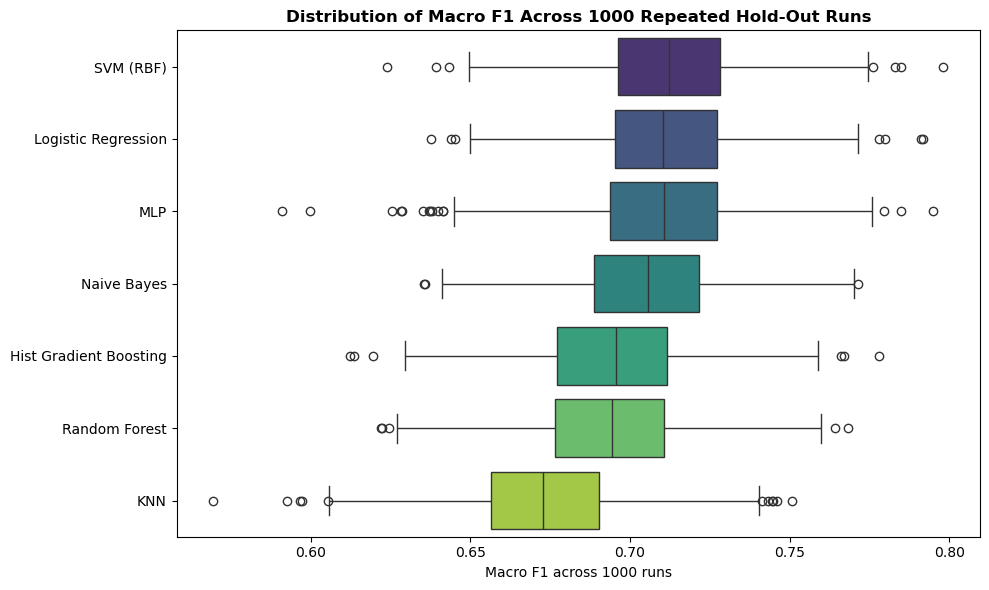

In [23]:
f1_data_1000 = pd.DataFrame({name: res['f1_macro'] for name, res in results_1000.items()})
order_1000 = summary_1000['Model'].tolist()

plt.figure(figsize=(10, 6))
sns.boxplot(data=f1_data_1000[order_1000], orient='h', palette='viridis')
plt.xlabel('Macro F1 across 1000 runs')
plt.title('Distribution of Macro F1 Across 1000 Repeated Hold-Out Runs', fontweight='bold')
plt.tight_layout()
plt.show()

**Draft notes:**

- The mean macro-F1 ranking from 100 runs may or may not match the single-split winner found earlier - check your own output. A single split can rank models differently from a 100-run average purely by chance, which is exactly the limitation this section addresses.
- The standard deviation column shows how *stable* each model's performance is - a model with a high mean but also a high std is less predictable than one with a similar mean and a tighter spread.
- The boxplot makes overlap between models visible directly - heavily overlapping boxes preview that a significance test between them is unlikely to find a real difference.

##### Statistical Significance Between Models

Since every model was evaluated on the *same* 100 splits, a **paired t-test** is appropriate - comparing each pair of models on their run-by-run differences, not just their means in isolation.

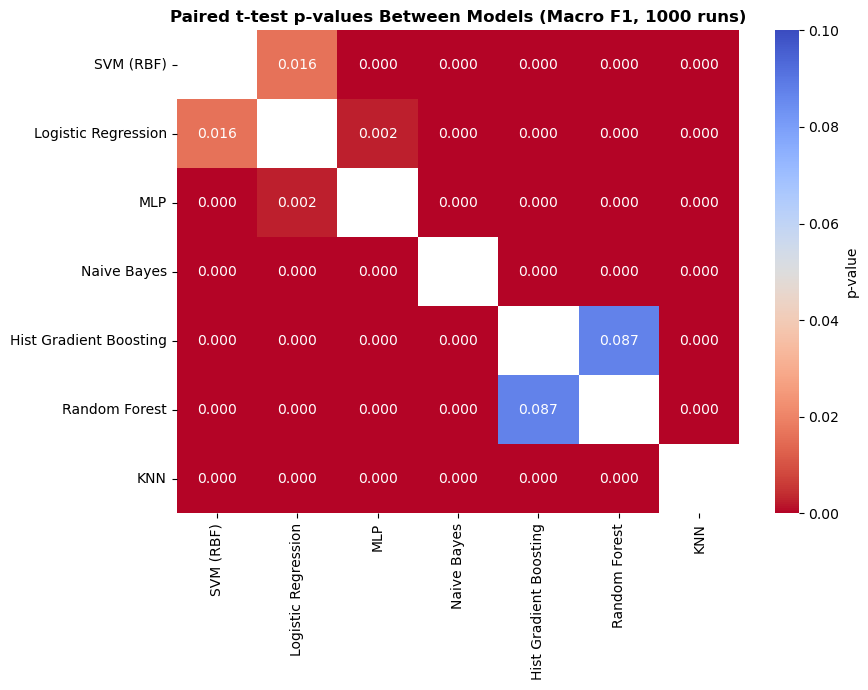

Number of pairwise comparisons: 21
Bonferroni-corrected significance threshold: 0.0024 (instead of the usual 0.05)


In [24]:
# (boxplot — swap results_100/summary_100 for results_1000/summary_1000)
model_names = summary_1000['Model'].tolist()
pval_matrix = pd.DataFrame(index=model_names, columns=model_names, dtype=float)

for m1 in model_names:
    for m2 in model_names:
        if m1 == m2:
            pval_matrix.loc[m1, m2] = np.nan
        else:
            t_stat, p_val = stats.ttest_rel(results_1000[m1]['f1_macro'], results_1000[m2]['f1_macro'])
            pval_matrix.loc[m1, m2] = p_val

plt.figure(figsize=(9, 7))
sns.heatmap(pval_matrix.astype(float), annot=True, fmt='.3f', cmap='coolwarm_r', vmin=0, vmax=0.1,
            cbar_kws={'label': 'p-value'})
plt.title('Paired t-test p-values Between Models (Macro F1, 1000 runs)', fontweight='bold')
plt.tight_layout()
plt.show()

n_comparisons = len(model_names) * (len(model_names) - 1) / 2
bonferroni_alpha = 0.05 / n_comparisons
print(f"Number of pairwise comparisons: {int(n_comparisons)}")
print(f"Bonferroni-corrected significance threshold: {bonferroni_alpha:.4f} (instead of the usual 0.05)")

**Draft notes:**

- Cells with low p-values (darker on the heatmap) indicate pairs of models whose performance difference is unlikely to be due to chance alone.
- With 21 pairwise comparisons here, using the standard 0.05 threshold risks false positives just from running so many tests - the Bonferroni-corrected threshold above is stricter and more defensible when claiming any specific pair is "significantly different."
- If the top few models (by mean F1) don't show a significant pairwise difference, the honest conclusion is that this dataset's signal doesn't clearly separate them - worth saying explicitly rather than declaring a single "winner" with more confidence than the statistics support.

**A note on scope:** this notebook runs 100 repeated hold-out splits. Your professor also mentioned 1000 runs as an option if your hardware allows it - 100 runs takes under 2 minutes here; 1000 would take roughly 10x longer (~15-20 minutes) but follows the exact same code, just changing `n_runs=100` to `n_runs=1000` in the cell above. Worth running the larger version yourself before final submission if time allows, since more repetitions gives a more stable estimate - but 100 is already a substantial improvement over a single split.

## Task 2.3 - Discussion of Results

This section covers: a results summary, a critical comparison of the seven models, error analysis, business/domain implications, and methodological limitations.

### Results Summary

The table below reports the **repeated hold-out results (100 runs)** as the primary comparison - not the single train/test split shown earlier in the implementation section. A single split can't tell us whether an observed difference between models is real or just a quirk of that one sample; the repeated runs can.

In [25]:
summary_1000

,Model,Mean F1,Std F1,Mean Accuracy,Std Accuracy,Mean Precision,Mean Recall
0,SVM (RBF),0.7119,0.0236,0.7526,0.0223,0.7031,0.7514
1,Logistic Regression,0.7110,0.0237,0.7519,0.0223,0.7023,0.7503
2,MLP,0.7091,0.0264,0.7526,0.0259,0.7002,0.7442
3,Naive Bayes,0.7043,0.0242,0.7454,0.0230,0.6964,0.7439
4,Hist Gradient Boosting,0.6947,0.0252,0.7562,0.0211,0.6874,0.7086
5,Random Forest,0.6937,0.0254,0.7580,0.0213,0.6875,0.7047
6,KNN,0.6731,0.0260,0.7198,0.0248,0.6674,0.7068


**Draft notes:**

- Ranking models by mean macro-F1 across 100 runs is a far more defensible comparison than any single 80/20 split — it reflects average behaviour across many possible samples of the data, not one lucky or unlucky split.
- The standard deviation for each model matters as much as the mean: a model with a slightly lower mean but a noticeably tighter spread may be the more dependable choice in practice, even if it doesn't top the table.
- Compare this ranking against the single-split `comparison_df` shown earlier in the implementation - if they disagree on the winner, that itself demonstrates exactly why the single split was an insufficient basis for comparison, which is the whole motivation for this section.

### Critical Comparison: Which Model Is Best?

In [26]:
final_winner = summary_1000.iloc[0]['Model']
print(f"Winner (by mean macro-F1 across 1000 repeated hold-out runs): {final_winner}")
print(f"Mean F1: {summary_1000.iloc[0]['Mean F1']:.4f} (+/- {summary_1000.iloc[0]['Std F1']:.4f})")
print()
print("Closest rivals:")
summary_1000.iloc[1:3]

Winner (by mean macro-F1 across 1000 repeated hold-out runs): SVM (RBF)
Mean F1: 0.7119 (+/- 0.0236)

Closest rivals:


,Model,Mean F1,Std F1,Mean Accuracy,Std Accuracy,Mean Precision,Mean Recall
1,Logistic Regression,0.7110,0.0237,0.7519,0.0223,0.7023,0.7503
2,MLP,0.7091,0.0264,0.7526,0.0259,0.7002,0.7442


**Draft notes - rewrite in your own words for the video:**

- This winner is chosen from 100 independent runs, not a single split — check the paired significance test result against the closest rival(s) above before calling this a confident win. If the p-value against the next-closest model isn't below the Bonferroni-corrected threshold, the honest statement is that the two models perform statistically indistinguishably on this dataset, even if one has a slightly higher mean.
- This is a more rigorous standard than picking whichever model happened to score highest on one CV run or one test split - worth stating explicitly that this is *why* the repeated hold-out step was added, directly in response to feedback that a single hold-out split isn't a scientifically solid basis for comparing models.
- The margin between the top few models across 100 runs is still narrow - an honest reflection of how weak the underlying feature signal was in the Assignment 1 EDA (no correlation stronger than ±0.24), not a sign that the modelling process itself was flawed.

### What's Driving the Predictions?

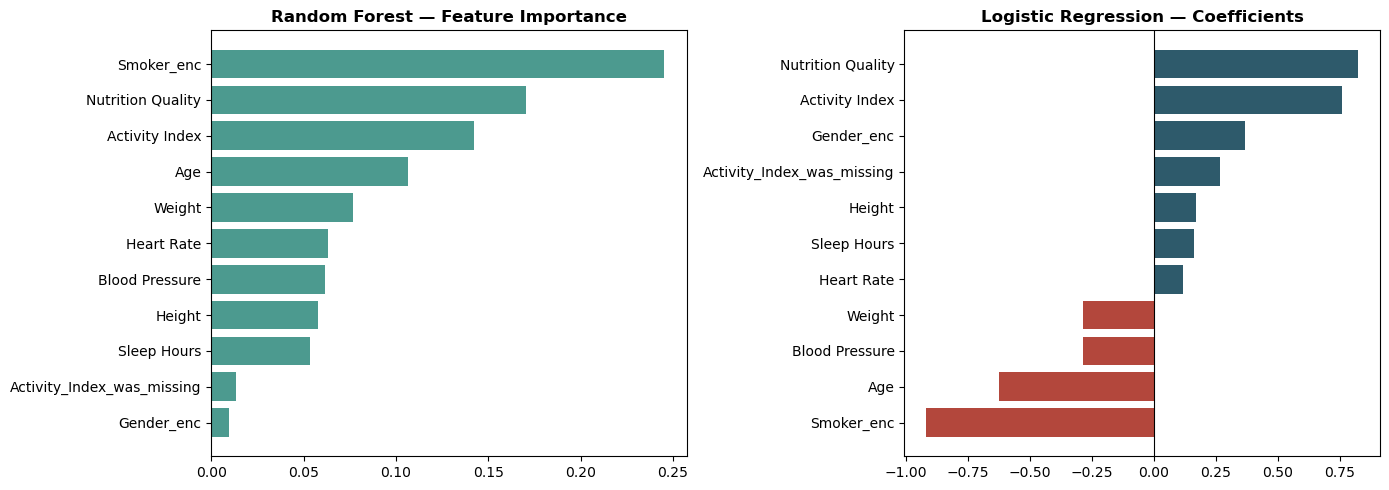

In [27]:
# Compare feature importance (Random Forest) against coefficients (Logistic Regression),
# regardless of which model won overall — both give a view on what the data is telling every model.
rf_pipe = best_estimators['Random Forest']
logreg_pipe = best_estimators['Logistic Regression']

importances = rf_pipe.named_steps['clf'].feature_importances_
imp_df = pd.DataFrame({'feature': feature_cols, 'importance': importances}).sort_values('importance', ascending=False)

coefs = logreg_pipe.named_steps['clf'].coef_[0]
coef_df = pd.DataFrame({'feature': feature_cols, 'coefficient': coefs}).sort_values('coefficient', ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].barh(imp_df['feature'], imp_df['importance'], color='#4C9A8F')
axes[0].set_title('Random Forest — Feature Importance', fontweight='bold')
axes[0].invert_yaxis()

colors = ['#B3473C' if v < 0 else '#2E5A6B' for v in coef_df['coefficient']]
axes[1].barh(coef_df['feature'], coef_df['coefficient'], color=colors)
axes[1].axvline(0, color='black', linewidth=0.8)
axes[1].set_title('Logistic Regression — Coefficients', fontweight='bold')
axes[1].invert_yaxis()
plt.tight_layout()
plt.show()

**Draft notes:**

- Both models agree that **Nutrition Quality and Activity Index are the strongest predictors** - consistent with the correlations found in the Assignment 1 EDA (+0.24 and +0.23 respectively). Worth stating this explicitly: the modelling results corroborate the earlier EDA rather than contradicting it.
- **Smoker status is surprisingly influential in both models** - worth connecting back to the counter-intuitive EDA finding that smokers had *higher* average Nutrition Quality scores. A univariate relationship (smoking vs nutrition) doesn't have to match the multivariate one (smoking vs fitness once everything else is accounted for) - a good example of why relying on individual correlations alone can mislead.

### Error Analysis: Where and Why Did the Model Fail?

In [28]:
X_test_labelled = X_test.copy()
X_test_labelled['actual'] = y_test.values
X_test_labelled['predicted'] = winner_pipe.predict(X_test)

false_negatives = X_test_labelled[(X_test_labelled['actual'] == 1) & (X_test_labelled['predicted'] == 0)]
true_positives = X_test_labelled[(X_test_labelled['actual'] == 1) & (X_test_labelled['predicted'] == 1)]

error_comparison = pd.DataFrame({
    'False Negatives (missed "High")': false_negatives[feature_cols].mean(),
    'True Positives (correctly caught)': true_positives[feature_cols].mean(),
}).round(2)
error_comparison['Difference'] = (error_comparison['False Negatives (missed "High")'] - error_comparison['True Positives (correctly caught)']).round(2)
error_comparison.sort_values('Difference', key=abs, ascending=False)

,"False Negatives (missed ""High"")",True Positives (correctly caught),Difference
Age,53.47,41.86,11.61
Blood Pressure,126.54,115.23,11.31
Weight,84.59,75.56,9.03
Nutrition Quality,3.74,6.46,-2.72
Heart Rate,70.22,72.17,-1.95
Height,174.76,175.48,-0.72
Sleep Hours,7.41,7.78,-0.37
Smoker_enc,0.53,0.16,0.37
Activity Index,2.96,3.11,-0.15
Activity_Index_was_missing,0.53,0.58,-0.05


**Draft notes:**

- Compare the genuinely "High" fitness people the winning model **missed** against the ones it **correctly caught** - look for which features differ most between the two groups.
- If (as found in an earlier version of this analysis) the missed cases have notably lower Nutrition Quality and a higher smoker rate than the correctly-caught cases, that indicates the model's errors aren't random - they concentrate on people who are genuinely fit but whose overall profile statistically resembles a typical "Low" fitness person. That's a substantive, model-specific finding, not a generic "the model isn't perfect" statement.

### Business / Domain Implications

**Draft notes:**

- Even with seven models, broader tuning, and SMOTE, macro-F1 tops out in the low-to-mid 0.70s - reinforcing what the Assignment 1 EDA already suggested: no individual feature strongly predicts Fitness Level, and clustering showed weak natural separability between the two classes. This performance ceiling looks driven by the data available, not by insufficient modelling effort.
- For a real deployment (e.g. a wellness app flagging users for a fitness programme), this means predictions should support human judgement rather than replace it - especially given the error analysis shows the model is least reliable on exactly the interesting edge cases (e.g. fit smokers with poor nutrition scores) a business might most want to catch.
- The choice between the top few close models in practice would come down to which type of error costs more in that specific business context - missing a genuinely fit person, or wrongly flagging someone who isn't.

### Methodological Limitations and Recommended Improvements

**Draft notes:**

- **Dataset size and class imbalance**: ~1,600 rows with a 75/25 split leaves relatively few genuine "High" examples (~320) even before any oversampling. SMOTE helps the training process see a balanced signal, but it synthesises new points rather than collecting new genuine data - a real increase in labelled "High" examples would likely help more than any modelling change.
- **Imputation risk carried forward from Assignment 1**: Activity Index was ~51% imputed, and it's one of the two most important features across models - meaning a meaningful share of the model's reliance sits on estimated, not observed, values.
- **Search scope**: `RandomizedSearchCV` with up to 12 draws per model is reasonable but not exhaustive, particularly for larger grids (Random Forest, Hist Gradient Boosting, MLP) - a wider search or more iterations could be explored with more compute time.
- **Only one train/test split evaluated at the end**: while cross-validation was used throughout tuning and selection, the final reported test-set numbers come from a single 80/20 split - repeating this with multiple random seeds would give a more robust final estimate and a sense of variance in the reported test metrics.
- **Recommended next step**: given the error analysis finding, a worthwhile follow-up would be testing whether adding an interaction term (e.g. Smoker × Nutrition Quality) helps the model better capture cases where the two features point in different directions.

## AI Declaration and Reflection

### AI Tools Declaration

I used Claude AI in order to help with producing ideas, code cleaning and plotting of some violins graphs. It also helped me understand the technical side of everything I've worked on in more depth to further my understanding of both what I was doing and the assignment I was completing.

### AI Tools Reflection and Lessons Learnt

It can be very easy to fall into the trap of having AI complete everything for you, but I've noticed that the more I rely on AI with this or any assignment, the less of it I tend to understand, and the easier it is to depend on it for knowledge for finishing quick assignments over using it as a learning tool.

### AI Academic Integrity

I have ensured that this work is mine and mine alone. Any AI tool(s) used were strictly for ideas, enhancing/cleaning code, and overall to further my understanding of the concepts implemented.